# PTM3D tutorial 01 — a global lunar diurnal run

One lunar day — a synodic month, 29.53 Earth days — of surface temperature over
the whole Moon on a coarse global mesh. This is the notebook counterpart of
[`01_quickstart.md`](../01_quickstart.md): same
config, same binary.

You will run the engine, read the run through one object, plot peak
temperature and the diurnal cycle, swap the smooth sphere for real LOLA
topography to see how much slope changes peak temperature and where, and
then change a thermophysical property and confirm that the change reached
the solver.

**Cost:** CPU-only, about a minute of engine time in total, under 1 GB
of RAM. Seven runs: three 1,280-face icospheres for the thermophysical
sweep in section 10, one more for its second arm, the quickstart itself,
and a pair of 20,480-face topography runs.
All have radiation exchange off — a convex sphere has no self-view — so no GPU
and no view-factor matrix are involved.

**Needs:** the `ptm` package (`pip install -e .` from the repository root), a
built `ptm_thermal_sim`, and the Moon SPICE kernels. The next cell checks for
all three and names the command that fixes anything missing.

In [1]:
from ptm import paths, run as engine

CONFIG = "examples/quickstart_moon_diurnal.yaml"
pre = paths.preflight([CONFIG, "data/kernels/lsk/naif0012.tls"],
                      engine="ptm_thermal_sim")
print(pre)
pre.raise_if_missing()

found    /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim
found    examples/quickstart_moon_diurnal.yaml
found    data/kernels/lsk/naif0012.tls

Repo root: /Users/paha3326/Projects/ptm-tut-thermophys
Engine:    /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim


<Report 3/3 found>

## 1. Run it

`run_engine` starts the engine, waits, and hands back what happened;
`.results()` opens the directory it wrote. With `echo=True` the engine's output
is streamed live, keeping one line per 25% of each progress bar so the executed
notebook stays readable.

Expect 5-10 s on a many-core workstation, up to a couple of minutes on a laptop
— the solver threads over whatever cores it finds.

In [2]:
moon = engine.run_engine(pre.root / CONFIG, echo=True).results()

Running: /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim --config /Users/paha3326/Projects/ptm-tut-thermophys/examples/quickstart_moon_diurnal.yaml
(cwd=/Users/paha3326/Projects/ptm-tut-thermophys)

╔═══════════════════════════════════════════════════════════════╗
║    *      .    *     \   ||    //      * .   .      *         ║
║       .      *     \  \  ||   //    //       .             .  ║
║  *      .       \   \  \  ☀  //    //      .      *           ║
║     .         *  \   ...-'''''-...//    *         .           ║
║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
║  ═══════════════════════════════════════════════════════════  ║
║      Coupled Thermal-Illumination for Planetary Bodies        ║
╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: /Users/paha3326/Projects/ptm-tut-thermophys/examples/quickstart_moon_diurna

========== Thermal Equilibration Configuration ==========
Body: Moon
Synodic day (solar day): 29.5306 Earth days
Equilibration cycles: 1.00 day/night cycles
Total equilibration period: 29.53 Earth days
Output window (for export): 29.53 Earth days
Requested integration (stats): 29.53 days with offset 0.00 days
Post-equilibration simulated span: 29.53 Earth days
Total simulation time: 59.06 Earth days
Time step calculation:
Requested output time steps: 240
Output window (days): 29.53
Output cadence:        8.127328 steps/Earth-day
Equilibration cadence: 8.127328 steps/Earth-day [legacy (matches output cadence)]
Total simulation days: 59.060588
Equilibration steps: 240
Output steps:        240
Total time steps (including equilibration and integration coverage): 480
Running illumination simulation for 59.060588 days (including 29.530588 days equilibration) starting at 2026-03-06T11:15:57
[IlluminationModel] mesh topology: CLOSED (watertight) (0 boundary edges / 1920 unique edges, 1280 core

Calculating illumination:  [=========================>                        ] 50% | elapsed 0s, ETA 0s
Calculating illumination:  [=====================================>            ] 75% | elapsed 0s, ETA 0s
Calculating illumination:  [==================================================] 100% | elapsed 0s
Illumination calculation completed in 0.378 seconds.
Results:
Average total flux: 455.993377907 W/m^2
- Direct solar: 455.961074443 W/m^2
- Primary reflected: 0.010316377 W/m^2
- Primary IR: 0.021987088 W/m^2
Maximum total flux: 1381.280797944 W/m^2
- Direct solar: 1381.280797944 W/m^2
- Primary reflected: 0.085032703 W/m^2
- Primary IR: 0.075130142 W/m^2
Minimum flux (non-zero): 0.000000000 W/m^2
Ray tracing computation completed in 0.380 seconds (380 ms)
[solar-const] incidence albedo uses the INSTANTANEOUS heliocentric solar constant (PTM-28 fix, default ON); S_inst range [1332.6, 1381.4] W/m^2
Verifying extracted illumination data:
Expected array size: 1280 * 480 = 614400
Illumin

Using 30 depth layers per profile
[eq-seed] equilibration seed: CPU SIMD-batch per-face steady state T=((<F_abs>+Qb)/(eps*sigma))^0.25, <F_abs> averaged over the first 100 forcing step(s), blended surface->deep over the skin depth [CPU batch path; not env-selectable]
SIMD Batch thermal [>                                                 ] 0% | elapsed 0s
SIMD Batch thermal [============>                                     ] 25% | elapsed 0s, ETA 0s
SIMD Batch thermal [=========================>                        ] 50% | elapsed 0s, ETA 0s
SIMD Batch thermal [=====================================>            ] 75% | elapsed 0s, ETA 0s
SIMD Batch thermal [==================================================] 100% | elapsed 0s
SIMD Batch thermal computation completed in 0.192 seconds (192 ms)
SIMD Batch thermal models completed successfully!
[Memory] Released combined illumination array (keeping per-component arrays for export)
[Integration] Statistics interval
Start (abs step): 240
Du

Body positions written to output/quickstart_moon_diurnal/body_positions.csv
Using binary output format for data files
[exportDataAsBinary] Starting binary export
Faces=1280 time_steps=240 components: illumination direct_solar primary_reflected primary_ir temperature


Progress 1/240


Progress 61/240


Progress 133/240


Progress 193/240


Progress 240/240
Export complete: 240/240
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_moon_diurnal
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
Face count: 1280
Time steps: 240
Computing illumination statistics...
Computing direct solar statistics...
Computing primary reflected statistics...
Computing primary IR statistics...
Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_moon_diurnal/statistics
[albedo] PTM-107(a) effective surface albedo (flux-weighted over the DIRECT beam, the value the BC absorbed with): global A_eff = 0.154457 over 1280/1280 ever-lit faces; per-face -> output/quickstart_moon_diurnal/statistics/effective_albedo.bin (uint32 n + float32[1280], NaN where never lit).
Reduced over the INTEGRATION window, abs steps [240,480) -- the same w

## 2. The first look

Peak temperature at every face over the lunation, drawn as orthographic globes.

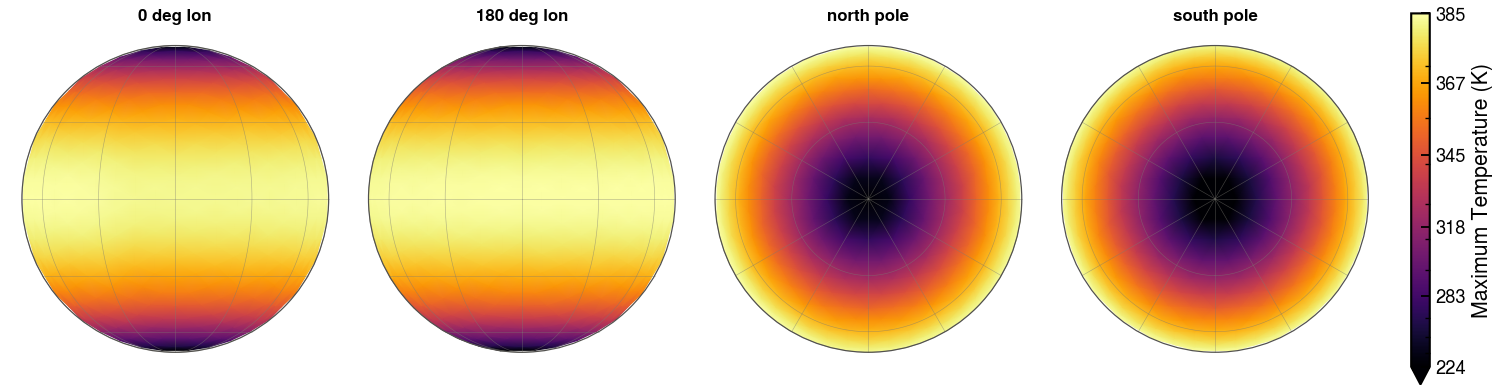

In [3]:
fig = moon.plot_globes("temperature", "max")

Three things are worth noticing before going any further.

The field is banded in latitude and flat in longitude, which is exactly what a
smooth sphere of uniform material must produce: every meridian gets the same
noon, so nothing distinguishes one from another. That makes the near-side and
far-side panels a useful null — any longitude structure appearing there in a
later run came from something the model added.

The cold caps are small. Stretched across the top of a rectangular map they
look like major provinces; on the globe each is a thumbprint.

The color scale is not linear in temperature. Section 5 explains why, and shows
what a linear one hides.

## 3. The config that produced it

[`examples/quickstart_moon_diurnal.yaml`](../../../examples/quickstart_moon_diurnal.yaml)
is a deliberately small "hello world" config, not a production one.

In [4]:
print((pre.root / CONFIG).read_text())

# PTM3D quickstart: global Moon diurnal run on a small icosphere (ico3, 1280 faces).
#
# Laptop-friendly (CPU-only, < 1 GB RAM, minutes of wall time). All paths are
# relative — run FROM THE REPOSITORY ROOT after fetching SPICE kernels:
#
#     python3 scripts/fetch_kernels.py --bodies moon   # once, ~44 MB from NAIF
#     (the bare command also fetches the 1.1 GB Galilean ephemeris for europa.tm)
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_moon_diurnal.yaml
#
# Outputs land in output/quickstart_moon_diurnal/ (per-face statistics binaries).
# See docs/tutorials/ for a walkthrough of the outputs.

simulation:
  start_time: '2026-04-05T00:00:00'
  duration_days: 29.53          # one synodic lunar day
  timesteps: 240                # ~3 h output cadence
  body: Moon
mesh:
  resolution: 3                 # icosphere subdivision level (1280 faces)
  import_file: ''
  scale_factor: 1.0
  use_topographic: false
thermal:
  run_thermal_mesh: true
  threads: 0                

The blocks that carry physics:

- **`simulation`** — `body: Moon` selects the built-in lunar ephemeris, radius,
  rotation and default regolith properties, so no `generic_body:` block is
  needed. `duration_days: 29.53` is one synodic month and `timesteps: 240` is
  the *output* cadence, about 3 h per step.
- **`thermal`** — `equilibration_orbits: 1.0` spins the solver up for one extra
  lunation *before* the output window opens, so the statistics carry no
  start-up transient. `run_thermal_mesh: true` puts a 1-D Crank-Nicolson
  conduction column under every face; `use_gpu: false` keeps everything on the
  CPU.
- **`thermophysical`** — on a built-in body only `use_default_albedo`,
  `incidence_angle_albedo` and the `*_override`/`*_model` keys are read. Plain
  property names (`albedo:`, `ks:`, `H:`) are honored only under a custom
  `generic_body.surface:` block; see
  [`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md).
  `incidence_angle_albedo: true` makes the *absorbed* flux use a Hapke
  directional-hemispheric albedo $A_h(i)$ built from the Moon's Bond albedo of
  0.12, rather than a flat 0.12 at every incidence angle.
- **`radiation.enabled: false`** — a smooth convex sphere has no face that can
  see another, so the view-factor and radiosity machinery has nothing to do.
  [`02_crater_radiosity.md`](../02_crater_radiosity.md) is the concave case.

## 4. What the run wrote

```
output/quickstart_moon_diurnal/
├── mesh.ply             # the 1,280-face icosphere; face order matches every .bin
├── metadata.txt         # faces, time steps, exported components
├── time_steps.txt       # per-step SPICE ET plus a UTC label
├── body_positions.csv   # Sun vector per output step
├── statistics/          # per-face min/avg/max over the output window
├── temperature/         # temperature_0000.bin .. temperature_0239.bin
├── illumination/        # total absorbed flux per step
├── direct_solar/        #   the direct solar component
├── primary_reflected/   #   Earth-reflected sunlight
└── primary_ir/          #   Earth thermal IR
```

Every `.bin` is a 4-byte little-endian face count followed by that many
`float32` values, one per face, in mesh-face order.
`ptm.Results` reads them and checks the count:
`stat(field, moment)` for a statistic, `field(field, step)` for one output step,
`stack(field)` for all of them. The full format reference is
[`03_outputs.md`](../03_outputs.md).

In [5]:
print(moon)
print("per-step fields:", ", ".join(moon.step_fields))
print("statistics     :", ", ".join(f"{f}_{m}" if m else f for f, m in moon.stats))

<Results quickstart_moon_diurnal: 1280 faces, 5 per-step field(s), 240 steps>
per-step fields: illumination, direct_solar, primary_reflected, primary_ir, temperature
statistics     : temperature_avg, temperature_max, temperature_min, illumination_avg, illumination_max, illumination_min, direct_solar_avg, direct_solar_max, direct_solar_min, primary_reflected_avg, primary_reflected_max, primary_reflected_min, primary_ir_avg, primary_ir_max, primary_ir_min, effective_albedo


In [6]:
import numpy as np

for moment in ("max", "avg", "min"):
    v = moon.stat("temperature", moment)
    print(f"temperature_{moment:3s}   min {v.min():6.1f}   median {np.median(v):6.1f}"
          f"   max {v.max():6.1f} K")

temperature_max   min  182.0   median  369.7   max  385.0 K
temperature_avg   min  107.2   median  208.1   max  216.4 K
temperature_min   min   66.3   median   92.6   max   95.9 K


Those three lines are the notebook's physical anchor. The hottest face reaches
**385 K** and the coldest bottoms out at **66 K**, matching the README's worked
example and tutorial 02 to a fraction of a kelvin. Both are checkable without
the model: equatorial noon at 0.98 AU with a Bond albedo of 0.12 gives
$T \approx (0.88\,S/\sigma)^{1/4} \approx 387$ K, and the median nighttime floor
lands on the ~90 K plateau Diviner measures.

## 5. Choosing a color scale for a planetary temperature field

A global temperature field is badly served by a linear color scale, for a
reason that is physics rather than taste. Radiative equilibrium puts the surface
at $T \propto (\cos i)^{1/4}$, and the quarter power flattens the whole sunlit
hemisphere: 30 degrees from the sub-solar point the insolation is down 13% but
the temperature is down only 3%. Most faces therefore sit within a few kelvin of
the peak while a thin polar tail occupies the rest of the range, so a linear
scale spends most of its colors on the tail and paints the body in one shade.

Two changes fix it, and both are used throughout these notebooks. A
perceptually uniform colormap (`inferno`, `ptm.plots.CMAP_FIELD`) makes equal
steps in the data look like equal steps in color and survives grayscale. And a
scale linear in $T^4$ rather than in $T$ (`ptm.plots.flux_norm`) undoes exactly
the compression the geometry introduced, because $\sigma T^4$ is the emitted
flux. The colorbar still reads in kelvin; its ticks are simply not evenly
spaced. Signed differences later use a diverging map centered on zero instead,
so "no change" is neutral and the sign is legible.

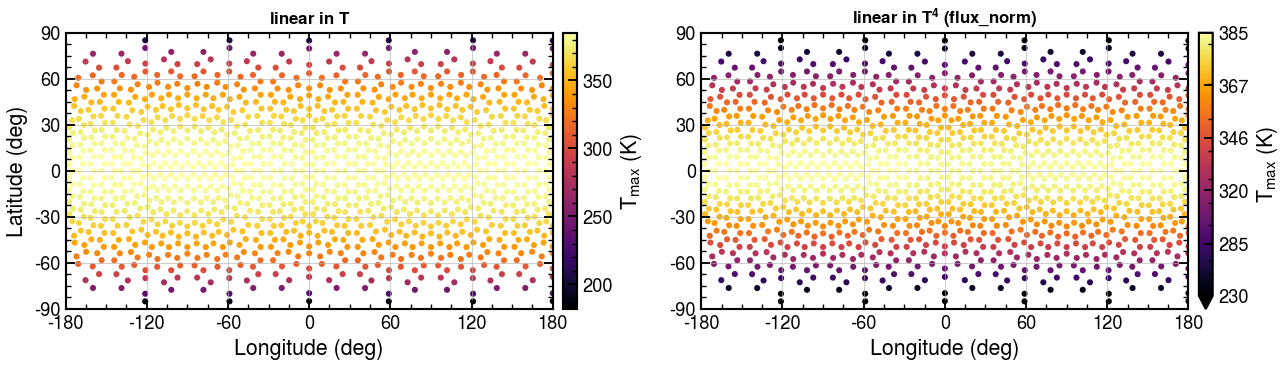

In [7]:
from matplotlib.colors import Normalize
from ptm import plots

plt = plots.styled()                 # the project's figure style
tmax = moon.stat("temperature", "max")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, norm, title in ((axes[0], Normalize(tmax.min(), tmax.max()), "linear in $T$"),
                        (axes[1], plots.flux_norm(tmax), "linear in $T^4$ (flux_norm)")):
    art = plots.scatter_map(ax, moon.lat, moon.lon, tmax, norm=norm, title=title,
                            ylabel=(ax is axes[0]))
    plots.colorbar(fig, art, ax, r"$T_\mathrm{max}$ (K)", tmax, norm,
                   pad=0.02, fraction=0.046)
fig.tight_layout()

Same numbers, both panels. On the left the middle half of the faces share about
a fifth of the color range and the sunlit hemisphere is one wash of pale yellow;
on the right the same faces are separated and the polar gradient is readable.

Each dot is one solved face at its own center — `plots.scatter_map` does not
regrid, so nothing here is interpolated.

## 6. The diurnal cycle at one face

`plot_diurnal` selects the face nearest a given latitude and longitude and plots
its whole time series.

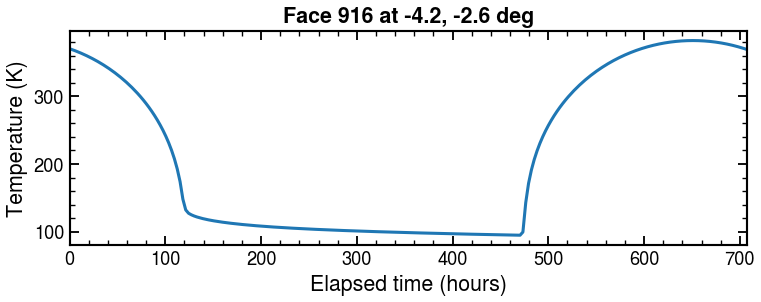

In [8]:
fig = moon.plot_diurnal(lat=0, lon=0)

The curve is the lunar day: a slow ~350 h rise to noon, then a slower fall. Peak
temperature and peak insolation land in the *same* output step for this face, so
the true thermal lag is shorter than the 3 h sampling and is not resolved here
(exercise 2 resolves it).

Thermal inertia shows most clearly in the shape of the night. Insolation goes to
zero at sunset in a single step — a geometric on/off — but temperature does not
follow. The surface falls steeply over the first several hours as the shallow
layer radiates, then the cooling rate collapses and it glides down almost linearly
for the rest of the ~450 h night. The glide is heat conducted up from deeper,
still-warm regolith, delayed by the thermal skin depth. It is the same nighttime
plateau Diviner sees.

## 7. Day/night contrast against latitude

Tmax - Tmin: 115.6 to 290.7 K, mean 264.9 K; correlation with |latitude| r = -0.92


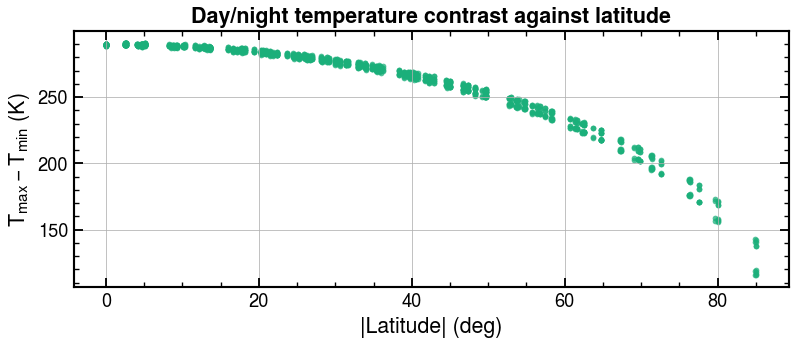

In [9]:
contrast = tmax - moon.stat("temperature", "min")
print(f"Tmax - Tmin: {contrast.min():.1f} to {contrast.max():.1f} K, "
      f"mean {contrast.mean():.1f} K; correlation with |latitude| "
      f"r = {np.corrcoef(np.abs(moon.lat), contrast)[0, 1]:+.2f}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.scatter(np.abs(moon.lat), contrast, s=14, alpha=0.75, linewidths=0, color="#1baf7a")
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel(r"$T_\mathrm{max} - T_\mathrm{min}$ (K)")
ax.set_title("Day/night temperature contrast against latitude")
ax.grid(True, linewidth=0.5)
fig.tight_layout()

The swing falls off cleanly toward the poles. Near the equator the Sun reaches
near-normal incidence at noon, so $T_\mathrm{max}$ approaches the sub-solar
blackbody limit, while the nighttime floor is the same ~90 K everywhere. Toward
the poles grazing incidence caps $T_\mathrm{max}$ well below the equatorial
value and $T_\mathrm{min}$ barely moves, so the swing narrows. This is why the
poles are cold-trap territory before any topographic shadowing enters — and
shadowing, added in tutorial 04, only deepens it.

## 8. One instant instead of a whole lunation

A window statistic and a single output step are different kinds of field. A
snapshot has a hot day side and a cold night side with a large population at
each end, spanning the full range, so it is *not* compressed and takes a plain
linear scale — the choice follows the distribution, not habit. `plot_globes`
applies the flux scale to peak temperature and a linear one to a single step for
that reason.

The `+` marks the sub-solar point, read from `body_positions.csv`, which records
the Sun vector in the body-fixed frame at every output step. At the step below
the Sun is over the far side, so the near-side panel is deep in lunar night —
the same trough the curve above traced in time.

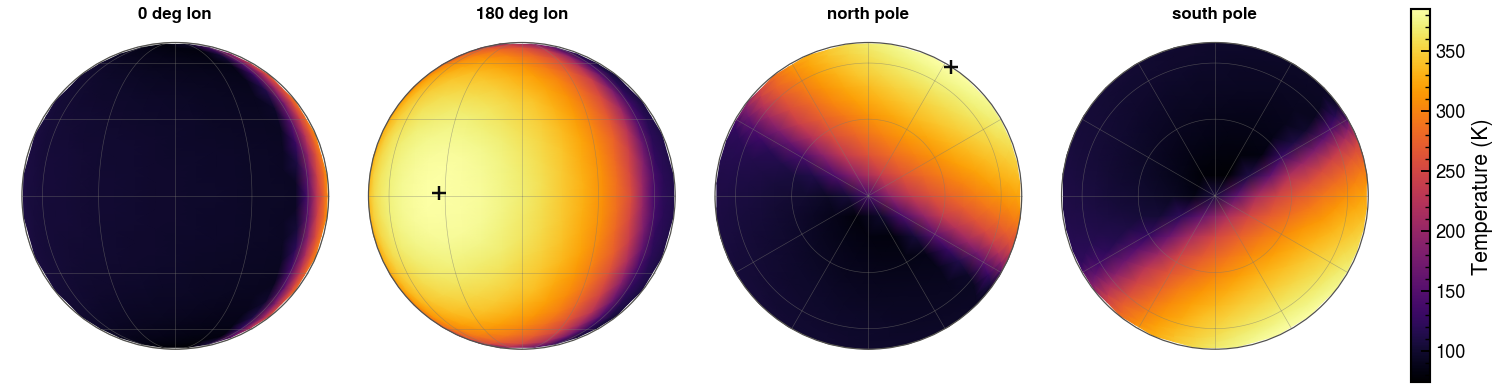

In [10]:
step = len(moon.times().et) // 2
fig = moon.plot_globes("temperature", step=step, mark_subsolar=True)

## 9. The same run on real lunar topography

Everything so far sits on a perfect sphere. PTM3D can instead displace every
mesh vertex to the real lunar radius from an LRO LOLA grid, which tilts each
face by the local slope and changes the incidence angle the solar beam sees.

The grids ship in the project's data distribution rather than in git:

```bash
python3 scripts/fetch_data.py --dataset moon-topo   # ico3-ico9, LOLA-derived
python3 scripts/fetch_data.py --core                # + property and albedo maps
```

Two configs make the comparison and differ in exactly one physics key,
`mesh.use_topographic`. Everything else — res-5 icosphere, 29.53 days, 240
steps, LOLA albedo map, Diviner H-parameter map — is identical, and because the
face count and connectivity are the same in both, the two outputs can be
differenced face by face.

In [11]:
TOPO = "examples/moon_global_topo_res5.yaml"
FLAT = "examples/moon_global_topo_res5_flat.yaml"
paths.preflight([TOPO, FLAT, "data/topo/moon/topo_moon_ico5.bin"]).raise_if_missing()

WATCH = ("Loading topographic mesh", "Mesh created with", "Simulation completed in")
topo = engine.run_engine(pre.root / TOPO, show=WATCH).results()
flat = engine.run_engine(pre.root / FLAT, show=WATCH).results()

    Mesh created with 10242 vertices and 20480 faces
    Loading topographic mesh from: data/topo/moon/topo_moon_ico5.bin
    Simulation completed in 8.522 seconds (8522 ms)


    Mesh created with 10242 vertices and 20480 faces
    Mesh created with 10242 vertices and 20480 faces
    Simulation completed in 8.320 seconds (8320 ms)


In [12]:
d_tmax = topo.stat("temperature", "max") - flat.stat("temperature", "max")
d_tmin = topo.stat("temperature", "min") - flat.stat("temperature", "min")
print(f"Tmax change (topography - smooth): mean {d_tmax.mean():+.2f} K, "
      f"RMS {d_tmax.std():.2f} K, range {d_tmax.min():+.1f} to {d_tmax.max():+.1f} K")
print(f"Tmin change:                       mean {d_tmin.mean():+.2f} K, "
      f"RMS {d_tmin.std():.2f} K")
print(f"|Tmax change| exceeds 5 K on {100 * np.mean(np.abs(d_tmax) > 5):.1f}% "
      f"of {topo.n_faces} faces")

Tmax change (topography - smooth): mean -0.01 K, RMS 3.38 K, range -71.4 to +105.3 K
Tmin change:                       mean -0.02 K, RMS 0.27 K
|Tmax change| exceeds 5 K on 5.5% of 20480 faces


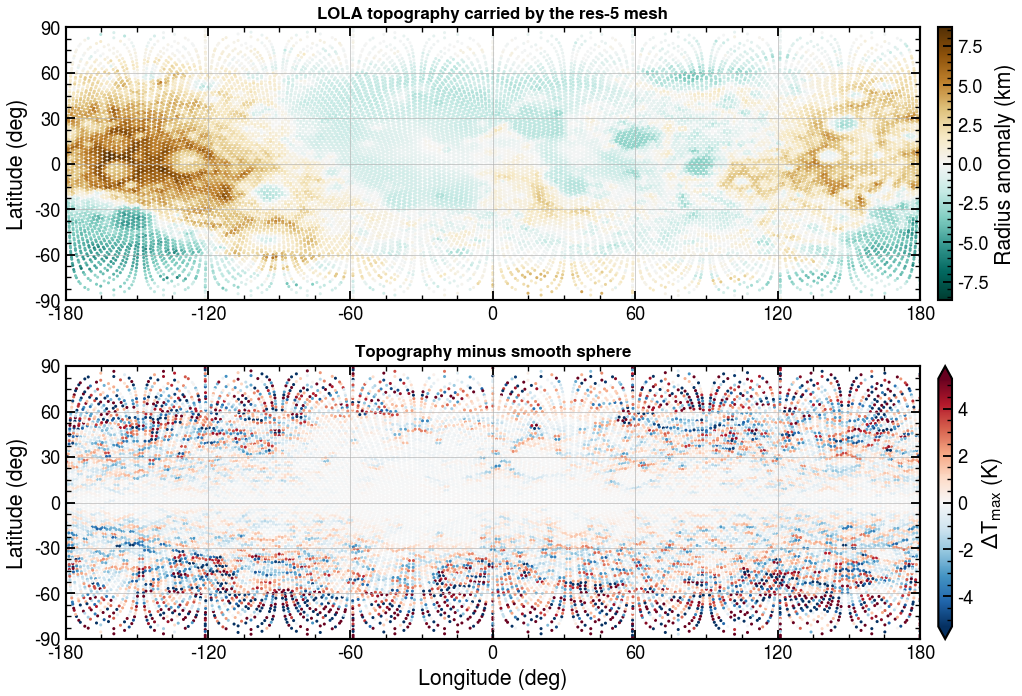

In [13]:
R_MOON_KM = 1737.4
radius = np.linalg.norm(topo.mesh["vertices"], axis=1)
relief = ((radius / np.median(radius) - 1.0) * R_MOON_KM)[topo.mesh["faces"]].mean(axis=1)
norm_d = plots.sym_norm(d_tmax, pct=95.0)

fig, axes = plt.subplots(2, 1, figsize=(9.5, 6.6))
for ax, values, cmap, norm, label, title in (
        (axes[0], relief, "BrBG_r", plots.sym_norm(relief, pct=100.0),
         "Radius anomaly (km)", "LOLA topography carried by the res-5 mesh"),
        (axes[1], d_tmax, plots.CMAP_DIFF, norm_d,
         r"$\Delta T_\mathrm{max}$ (K)", "Topography minus smooth sphere")):
    art = plots.scatter_map(ax, topo.lat, topo.lon, values, cmap=cmap, norm=norm,
                            title=title, xlabel=(ax is axes[-1]))
    plots.colorbar(fig, art, ax, label, values, norm, pad=0.02, fraction=0.046)
fig.tight_layout()

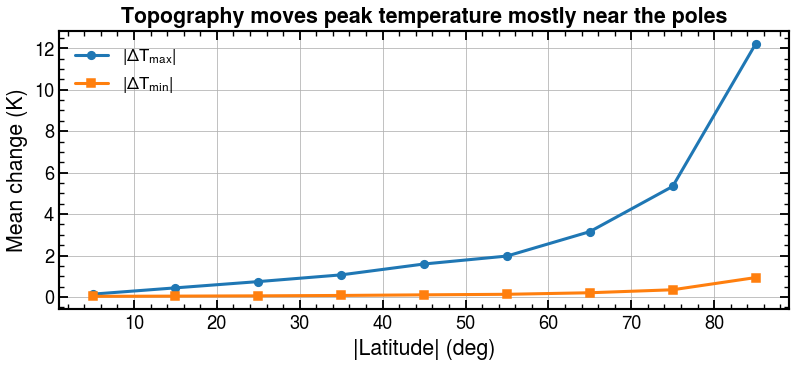

In [14]:
edges = np.arange(0, 91, 10)
abs_lat = np.abs(topo.lat)
binned = lambda d: [np.abs(d[(abs_lat >= a) & (abs_lat < b)]).mean()
                    for a, b in zip(edges[:-1], edges[1:])]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(edges[:-1] + 5, binned(d_tmax), "o-", lw=2, label=r"$|\Delta T_\mathrm{max}|$")
ax.plot(edges[:-1] + 5, binned(d_tmin), "s-", lw=2, label=r"$|\Delta T_\mathrm{min}|$")
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel("Mean change (K)")
ax.set_title("Topography moves peak temperature mostly near the poles")
ax.legend(frameon=False)
ax.grid(True, linewidth=0.5)
fig.tight_layout()

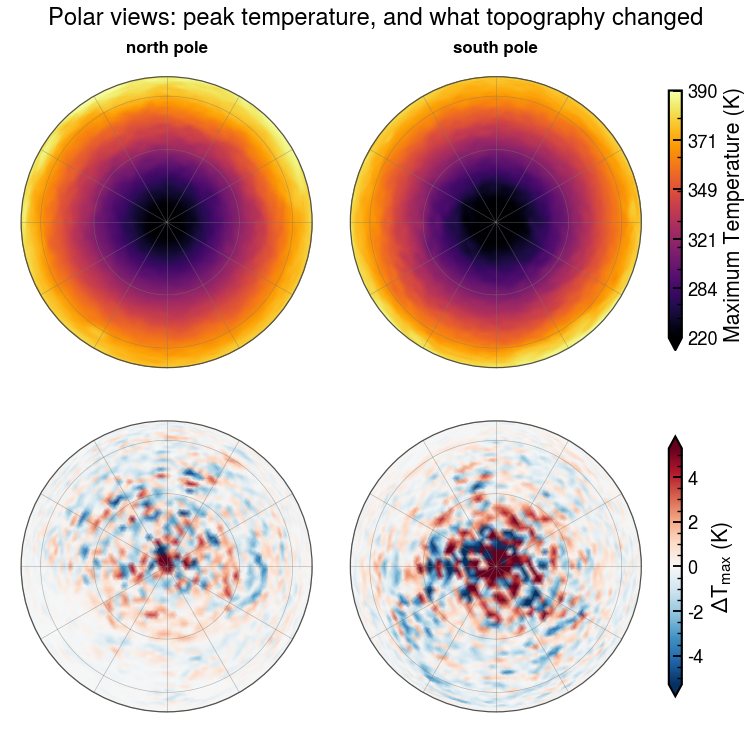

In [15]:
fig = topo.globe_grid(
    rows=[{"what": "temperature", "moment": "max"},
          {"what": d_tmax, "label": r"$\Delta T_\mathrm{max}$ (K)",
           "cmap": plots.CMAP_DIFF, "norm": norm_d}],
    views=[(90, 0, "north pole"), (-90, 0, "south pole")],
    suptitle="Polar views: peak temperature, and what topography changed")

**The mean is not the story.** Averaged over the Moon, topography changes
$T_\mathrm{max}$ by essentially nothing, and it should: a slope tilted toward
the noon Sun is matched elsewhere by one tilted away. The *spread* is what
matters — several kelvin RMS, with extreme faces moving by tens of kelvin.

**The effect is a polar effect.** The binned curve rises steeply with latitude,
for the same quarter-power reason that motivated the color scale. With the Sun
near the zenith, tilting a face by a degree barely changes $\cos i$; with the
Sun a few degrees above the horizon, the same tilt is a large *fractional*
change in $\cos i$, and near-grazing faces swing by tens of kelvin. Polar
thermal modeling is therefore topography modeling, which is why the
crater-scale tutorials use DEM meshes rather than global icospheres.

**Night temperatures barely notice.** The change in $T_\mathrm{min}$ is an order
of magnitude smaller. After sunset there is no illumination geometry left to
care about: the floor is set by how much heat the regolith stored and how fast
it conducts, and a slope changes neither.

**What this does not cover.** Both arms carry the same albedo and H-parameter
maps, so the difference is geometry alone — but only at res-5, where one face
spans roughly 250 km. That resolves the great basins, not craters, and with
`radiation.enabled: false` no face shadows another. For the shadowing that makes
real polar craters cold traps, see [`02_crater_radiosity.md`](../02_crater_radiosity.md).

## 10. Changing a thermophysical property

Changing a surface property and looking at what moved is what most people want
a thermal model for. On a built-in body the properties come from a compiled
table, so a config edit reaches the solver only through the channels the engine
reads for that table, and reaching for the wrong one is quiet. This section is
a worked sweep plus the two habits that confirm a sweep did anything.

On a built-in body (`body: Moon`, `body: Europa`, ...) these are read:

| to change | use |
|---|---|
| surface and deep conductivity | `thermophysical.ks_override`, `kd_override` |
| Bond albedo, emissivity | `thermophysical.albedo_override`, `emissivity_override` |
| thermal inertia, one number | `--thermal-inertia`, or `thermophysical.constant_thermal_inertia` |
| thermal inertia, per face | `thermal.thermal_inertia_map` |
| H-parameter, per face | `thermophysical.h_parameter_map` |
| internal heat flux, per face | `thermophysical.heat_flow_mask_file` |
| the conduction law itself | `thermophysical.conductivity_model` |
| the angular albedo treatment | `thermophysical.incidence_angle_albedo` |

The plainly-named keys — `thermophysical.albedo`, `ks`, `kd`, `rhos`, `rhod`,
`cp0`, `H`, `Qb`, `chi` — are **not** read here. They belong under
`generic_body.surface:`, which is tutorial 03's path; the
engine prints one warning line naming any of them it finds under
`thermophysical:`. Two more change nothing on this path even though they sit in the
same block: `albedo_hapke_w` and `thermal_n`, both of which leave the run
byte-identical. One is worse than dead: `thermal.geothermal_heat_flow` prints
`Overriding planet geothermal heat flow` and then integrates the compiled
default anyway, so a per-face `heat_flow_mask_file` is the way to set an
internal heat flux you can rely on.

### Thermal inertia is derived, so there are two of it

$\Gamma = \sqrt{k \rho c_p}$ is not stored anywhere. Asking for
$\Gamma = 200$ means changing $k$, or $\rho$, or $c_p$, and the engine
implements two of those choices:

- **`thermal_inertia`** (`--thermal-inertia`) sets
  $k_s = \Gamma^2 / (\rho_s\, c_p(273\,\mathrm{K}))$ and scales $k_d$ by the
  same factor. The surface-to-depth contrast and the radiative conductivity
  term $\chi$ survive, so the delivered inertia still varies with depth and
  temperature — 200 is a nominal surface value.
- **`constant_thermal_inertia`** (`--constant-thermal-inertia`, or the config
  key of the same name) derives $c_p$ instead and sets $\chi = 0$,
  $k_d = k_s$, $\rho_d = \rho_s$, so $\Gamma$ is exactly constant in
  temperature *and* in depth.

Reach for the first to scale a real regolith column, and the second when you
want one number that stays that number, which is usually what a radiometric fit
reports. They are different physics, the difference is measured at the end of
this section, and the engine refuses a run that is given both.

In [16]:
from ptm import Sweep

ti_sweep = Sweep(pre.root / CONFIG, grid={"thermal_inertia": [100.0, 200.0, 400.0]},
                 outdir=pre.root / "output/moon_thermal_inertia_sweep")
ti_sweep.run()

[sweep] engine /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim (md5 04287bb7c7fb230d31588e8a11491ac8)
[sweep] axis thermal_inertia: 3 values -> --thermal-inertia (engine advertises it)
[sweep]   note (thermal_inertia): this is ks = TI^2/(rhos*cp(273 K)) with kd scaled by the same factor: the depth contrast is preserved and the diffusivity moves with TI. The other convention, constant_thermal_inertia, derives cp instead and collapses the column -- 39.27 K vs 42.19 K diurnal amplitude at TI=200 on quickstart_asteroid_diurnal. Choose deliberately.


[sweep] ok   thermal_inertia-100 (4.2 s)


[sweep] ok   thermal_inertia-200 (4.2 s)


[sweep] ok   thermal_inertia-400 (4.2 s)
[sweep] 3 complete, 0 failed, 0 skipped, 12.7 s


{'planned': 3,
 'skipped': 0,
 'complete': 3,
 'failed': 0,
 'not_attempted': 0,
 'wall_seconds': 12.7,
 'dry_run': False}

`Sweep` takes one base config it never edits, a grid, and writes one run
directory per point. Before launching anything it says which route each axis
took — here the engine advertises `--thermal-inertia`, so the axis goes by flag
— and repeats the warning about the two conventions.

Two habits turn that into confirmation.

**One: read back the value the solver used.** The engine prints
`Property override (requested):` when it parses the request and
`[Thermo override] applied at solver:` when the solver takes delivery. Only the
second is evidence. The `--thermal-inertia` route shows both numbers it
computed, which is also the quickest way to see that $\Gamma = 200$ on the Moon
means $k_s = 0.0505$ W/m/K, a long way from the 0.00074 the body ships with.

**Two: two points of a sweep must not produce identical output.** A checksum
over `statistics/temperature_max.bin` catches a dead axis whatever the log
said, and costs nothing.

In [17]:
import hashlib

digests = []
for point in ti_sweep.points:
    log = (point.dir / "engine.log").read_text().splitlines()
    applied = next((l for l in log if "applied at solver:" in l), "NO OVERRIDE LINE")
    digests.append(hashlib.md5(
        (point.dir / "statistics" / "temperature_max.bin").read_bytes()).hexdigest())
    print(f"TI = {point.params['thermal_inertia']:5.0f}  {digests[-1][:8]}  {applied}")
print(f"\n{len(set(digests))} distinct outputs from {len(digests)} sweep points")

TI =   100  379f4777  [Thermo override] applied at solver: ks 0.00074 -> 0.012632 W/m/K; kd 0.0034 -> 0.0580388 W/m/K
TI =   200  8829e3c6  [Thermo override] applied at solver: ks 0.00074 -> 0.0505279 W/m/K; kd 0.0034 -> 0.232155 W/m/K
TI =   400  dca8f174  [Thermo override] applied at solver: ks 0.00074 -> 0.202112 W/m/K; kd 0.0034 -> 0.928621 W/m/K

3 distinct outputs from 3 sweep points


A misspelled key is the case neither habit is aimed at, because nothing
misfires: the engine reads YAML it does not recognize without complaint, and so
does the command line — `--not-a-real-flag 3` is accepted in silence and the run
proceeds. Inside `thermophysical:` the engine does name keys it will not read.
Everywhere else, `ptm.engine_config.unknown_keys` is the check, and it works on
a config dictionary before anything is launched.

In [18]:
import yaml
from ptm.engine_config import unknown_keys

draft = yaml.safe_load((pre.root / CONFIG).read_text())
draft["thermophysical"]["ks"] = 0.003            # a plain name: not read on a built-in body
draft["thermal"]["equilibration_orbit"] = 4.0    # a misspelling of equilibration_orbits
print("read by nothing:", unknown_keys(draft))

read by nothing: ['thermal.equilibration_orbit', 'thermophysical.ks']


In [19]:
const_sweep = Sweep(pre.root / CONFIG, grid={"constant_thermal_inertia": [200.0]},
                    outdir=pre.root / "output/moon_constant_ti_sweep")
const_sweep.run()

[sweep] engine /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim (md5 04287bb7c7fb230d31588e8a11491ac8)
[sweep] axis constant_thermal_inertia: 1 values -> --constant-thermal-inertia (engine advertises it)
[sweep]   note (constant_thermal_inertia): this is cp = TI^2/(ks*rhos) with chi=0, kd=ks and rhod=rhos: TI is exactly constant in temperature AND depth, and the thermal diffusivity therefore varies along the axis. The other convention, thermal_inertia, scales ks/kd instead -- 42.19 K vs 39.27 K diurnal amplitude at TI=200 on quickstart_asteroid_diurnal. Choose deliberately.


[sweep] ok   constant_thermal_inertia-200 (4.3 s)
[sweep] 1 complete, 0 failed, 0 skipped, 4.3 s


{'planned': 1,
 'skipped': 0,
 'complete': 1,
 'failed': 0,
 'not_attempted': 0,
 'wall_seconds': 4.3,
 'dry_run': False}

amplitude at TI = 200: 196.3 K by one convention, 241.2 K by the other (+44.9 K)


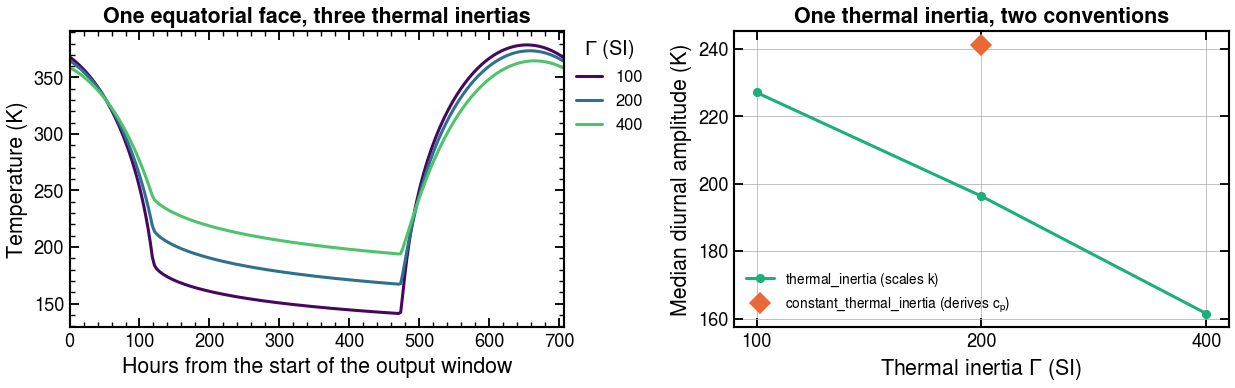

In [20]:
def amplitude(res):
    return float(np.median(res.stat("temperature", "max") - res.stat("temperature", "min")))


ti, amp = ti_sweep.values("thermal_inertia"), ti_sweep.collect(amplitude)
amp_const = amplitude(const_sweep.points[0].results)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ti_sweep.plot_curves(ax=axes[0], lat=0, lon=0, legend_title=r"$\Gamma$ (SI)",
                     xlabel="Hours from the start of the output window",
                     title="One equatorial face, three thermal inertias")
axes[1].plot(ti, amp, "o-", lw=2, color="#1baf7a", label=r"thermal_inertia (scales $k$)")
axes[1].plot([200.0], [amp_const], "D", ms=9, color="#eb6834",
             label=r"constant_thermal_inertia (derives $c_p$)")
axes[1].set_xscale("log")
axes[1].set_xticks(ti)
axes[1].set_xticklabels([f"{v:g}" for v in ti])
axes[1].minorticks_off()
axes[1].set_xlabel(r"Thermal inertia $\Gamma$ (SI)")
axes[1].set_ylabel("Median diurnal amplitude (K)")
axes[1].set_title("One thermal inertia, two conventions")
axes[1].legend(frameon=False, fontsize=9)
axes[1].grid(True, linewidth=0.5)
fig.tight_layout()
print(f"amplitude at TI = 200: {amp[1]:.1f} K by one convention, "
      f"{amp_const:.1f} K by the other ({amp_const - amp[1]:+.1f} K)")

**The signature is the one conduction predicts.** Raising $\Gamma$ flattens the
curve toward its mean: the median face swings 227.1 K at 100 SI, 196.3 K at 200
and 161.5 K at 400. The left panel shows where that comes from — the peak drops
a little and the night floor rises a lot, because a higher inertia stores more
of the day's heat and gives it back through the night.

**The convention costs more than a factor of two in $\Gamma$.** At the same
nominal 200 SI the two conventions give 196.3 K and 241.2 K, 44.9 K apart —
larger than the 30.8 K that doubling $\Gamma$ from 100 to 200 produces along
the swept convention. Quoting "$\Gamma = 200$" without saying which convention
produced it leaves the reader a 23% ambiguity in the headline number.

**None of these three is the Moon.** The body ships with
$k_s = 7.4\times10^{-4}$ W/m/K, which on this same nominal-surface convention
is $\Gamma = 24$ SI — the 50-70 SI usually quoted for lunar regolith is an
effective value over the diurnal skin depth, and it already includes the rise of
$k$ with depth and the radiative term. Every point on this sweep therefore has a
warmer, flatter night than the real Moon. It is a sensitivity study around a
body, not a model of one.

**What this does not cover.** One property, uniform over the whole body, on a
convex sphere with `radiation.enabled: false` — so no self-heating feedback
amplifies or damps the response, and nothing here says how the same change
behaves inside a crater. Per-face variation is the other route entirely
(`thermal.thermal_inertia_map`, and the H-parameter and albedo maps section 9
already used). Tutorial 03 does the same exercise on a generic body, where the
plainly-named properties are the live ones.

## 11. Exercises

1. **Sharper map, config change only.** Copy the quickstart config and raise
   `mesh.resolution` from `3` to `4` (1,280 to 5,120 faces). Re-run section 1
   against the new config and redraw section 5's map.
   `scripts/ptm_mem_estimate.py --faces 5120 --steps 240` sizes it first.

2. **Resolve the noon lag.** Peak insolation and peak temperature share an
   output step above, so the real lag is shorter than 3 h. Raise
   `simulation.timesteps` from `240` to `960` (about 45 min per step) and see
   whether the two peaks separate.

3. **Poles against equator, no re-run.** `moon.plot_diurnal(lat=85, lon=0)` is
   the whole change. Expect a much smaller swing, consistent with section 7, and
   a flatter shape: grazing incidence spreads a weaker flux over more of the day.

4. **Resolve the topography.** Set `mesh.resolution: 6` in both section 9
   configs (81,920 faces; `topo_moon_ico6.bin` ships with the same dataset). The
   mean change should stay near zero while the RMS grows, because a finer mesh
   resolves steeper slopes.

5. **Sweep something other than thermal inertia.** Section 10's cell changes
   one word: `grid={"albedo": [0.08, 0.12, 0.16]}` spans the lunar range, and
   `grid={"thermophysical.emissivity_override": [0.90, 0.95, 1.00]}` shows how
   little emissivity moves peak temperature next to albedo. Both need the
   checksum habit, because both are cheap to misspell.

A note on thermophysical exercises: `body: Moon` is a built-in body, so plain
property names in a config are not read (sections 3 and 10). Section 10's
`Sweep` is the shortest route to any of the channels that are, and tutorial 03
works entirely on the `generic_body:` path where the plain names are live.
